# 蔬菜批发报价异常检测与采购复核

业务问题：采购每天应优先复核哪些报价？

使用新发地单市场公开报价，展示数据质检、日历时间统计、规则检测、阈值工作量评估及 SQL 校验。
数据覆盖 2026-01-01 至 2026-08-11；这是历史行情回放，不代表实时价格，也未验证提前预测能力。
同品种不同规格/产地的报价使用非成交量加权均值，因此结构变化也可能影响价格。

## 0. 准备

在仓库根目录运行 `pip install -r requirements.txt -r requirements-dev.txt -r requirements-notebook.txt`。
Notebook 可从仓库根目录或 notebooks/ 启动，产物写入 outputs/。无须外部服务或 Webhook。

In [1]:
import sys
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == 'notebooks' else CWD
sys.path.insert(0, str(ROOT / 'scripts'))
import run_veg_monitor as monitor
import evaluate_monitor as evaluation
import run_sql_analysis as sql_analysis
get_ipython().run_line_magic("matplotlib", "inline")

OUT = ROOT / 'outputs'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
df = monitor.load_data(ROOT / 'data' / 'veg_wholesale_xinfadi.csv')
features = monitor.compute_features(df)
v = monitor.classify_anomalies(features)
summary = monitor.build_summary(v)
print(f'{len(df):,} 条报价，{df["product"].nunique()} 个品种，{df.date.nunique()} 个有报价日期')
df.head()

22,362 条报价，145 个品种，216 个有报价日期


,date,product,avg_price,low_price,high_price,n_records,origin
0,2026-01-01,丝瓜,5.15,4.5,5.8,1,冀/豫
1,2026-01-02,丝瓜,5.05,4.5,5.6,1,冀/豫
2,2026-01-03,丝瓜,5.05,4.5,5.6,1,冀/豫
3,2026-01-04,丝瓜,5.05,4.5,5.6,1,冀/豫
4,2026-01-05,丝瓜,5.05,4.5,5.6,1,冀/豫


## 1. 数据质量：先确认哪些比较有效

缺失产地统一为空字符串，只有连续两天且双方产地已知才判断产地变化。
省级单字简称按集合规范化，例如“鲁冀”和“冀/鲁”相同；未知地名不猜测。
缺失日期不补价，跨日变动单独保留为 observed_pct_ch，不触发单日规则。

重复品种日             0.000000
缺失产地条数         4654.000000
缺失产地比例            0.208121
间隔超过一天的相邻记录    1516.000000
最长相邻记录间隔（天）      18.000000
不足30条报价的品种       38.000000
可参与风险排名的品种      107.000000


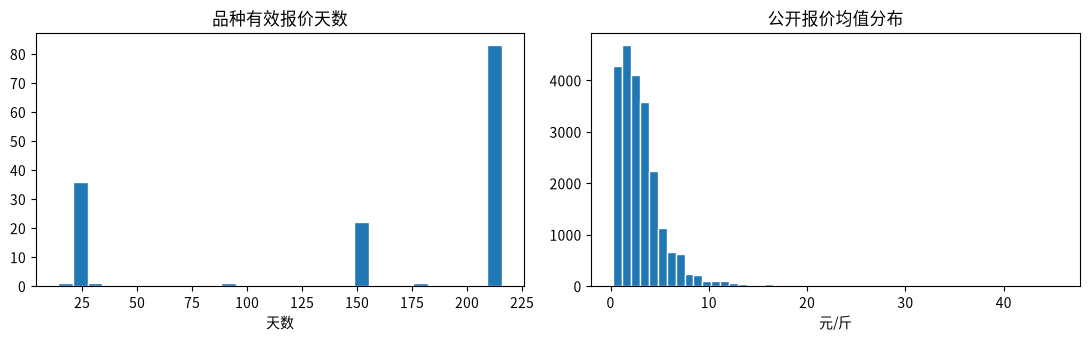

In [2]:
coverage = df.groupby('product').date.nunique()
quality = pd.Series({
    '重复品种日': int(df.duplicated(['product', 'date']).sum()),
    '缺失产地条数': int(df.origin.eq('').sum()),
    '缺失产地比例': df.origin.eq('').mean(),
    '间隔超过一天的相邻记录': int(features.gap_days.gt(1).sum()),
    '最长相邻记录间隔（天）': features.gap_days.max(),
    '不足30条报价的品种': int(coverage.lt(30).sum()),
    '可参与风险排名的品种': int(summary.rank_eligible.sum()),
})
print(quality.to_string())
assert not (v.origin_shift_alert & ~v.origin_comparable).any()
assert v.loc[v.gap_days.ne(1), 'price_pct_ch'].isna().all()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(coverage, bins=30, edgecolor='white')
axes[0].set(title='品种有效报价天数', xlabel='天数')
axes[1].hist(df.avg_price, bins=50, edgecolor='white')
axes[1].set(title='公开报价均值分布', xlabel='元/斤')
fig.tight_layout()
fig.savefig(OUT / 'figures' / 'eda_coverage.png', dpi=150)
plt.show()

## 2. 描述价格走势

选择叶菜、大路菜及果菜观察；不同覆盖天数与规格结构会影响比较。
图中的时间变化只是描述性证据，不能单凭这些图确认天气、节假日或供需的因果影响。

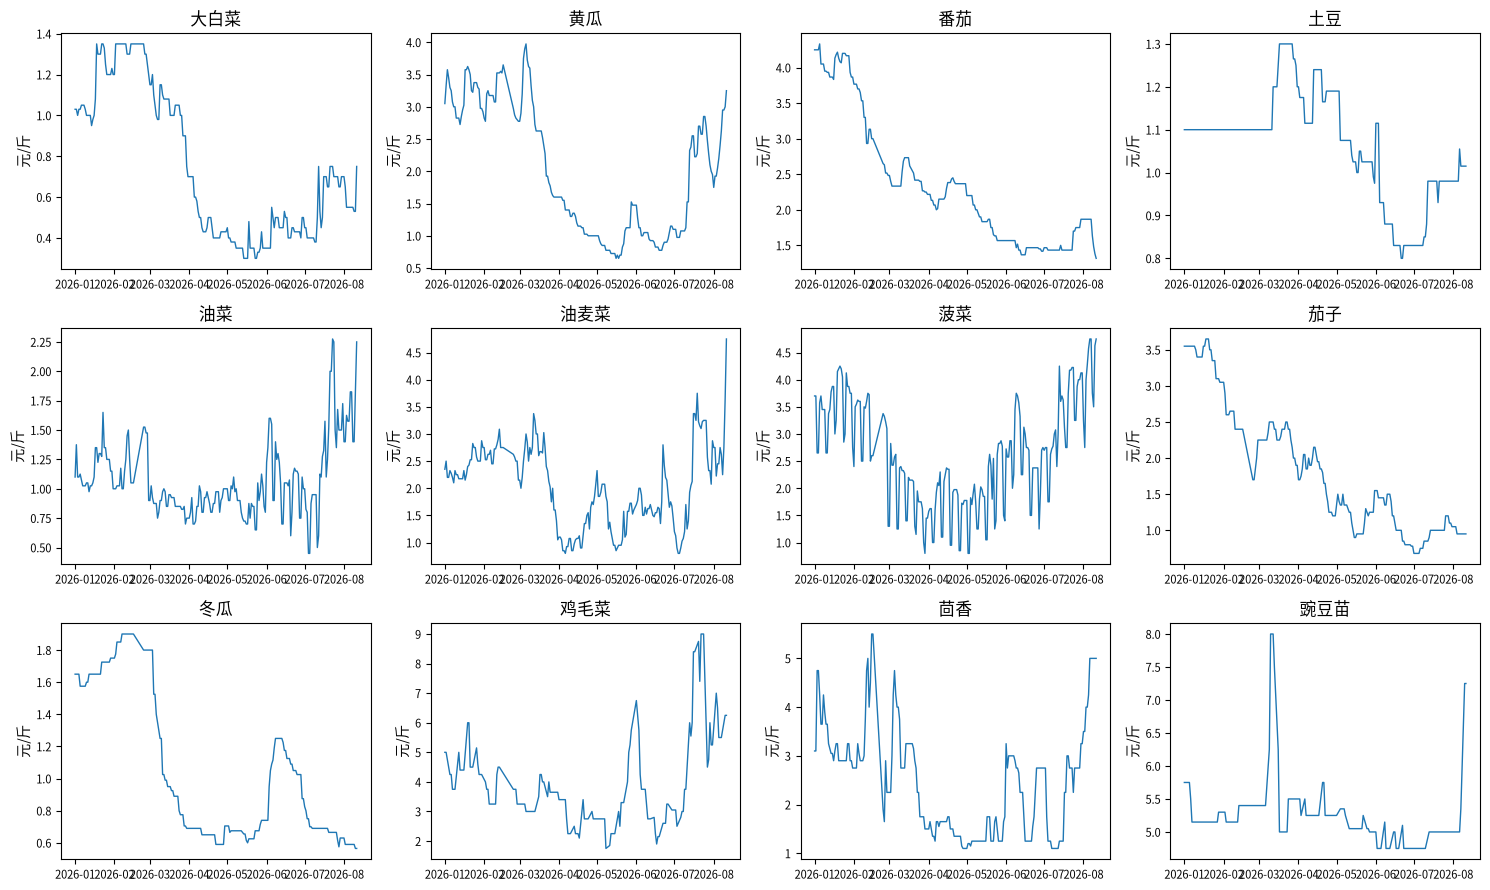

In [3]:
sample = ['大白菜', '黄瓜', '番茄', '土豆', '油菜', '油麦菜',
          '菠菜', '茄子', '冬瓜', '鸡毛菜', '茴香', '豌豆苗']
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, product in zip(axes.ravel(), sample):
    part = df[df["product"].eq(product)].sort_values('date')
    ax.plot(part.date, part.avg_price, linewidth=1)
    ax.set(title=product, ylabel='元/斤')
    ax.tick_params(labelsize=8)
fig.tight_layout()
fig.savefig(OUT / 'figures' / 'eda_ts_sample.png', dpi=150)
plt.show()

## 3. 检测口径与风险评分

- z-score：当日价格相对于 **[t−30 日, t)** 的均值和样本标准差，至少 15 条历史报价，基准排除当日。
- 历史标准差为零时：价格不变记 z=0，价格变化记有符号无穷值；历史不足仍不可评估。
- 急涨/急跌：连续日历天的环比达到 +15% / −12%。
- 持续高位：z>2 连续至少三个日历天；缺日会中断。
- 产地切换：连续两天、双方产地已知、产地集合不同，且价格变化绝对值至少 5%。
- 异常总数按品种日去重，类型计数允许重叠。
- 风险评分：10×平均14日波动率 + 100×(3×价格异常率 + 急涨率 + 急跌率 + 2×产地切换率 + 2×持续高位率)。
  各分项按对应有效比较日计率；无可用产地比较时该分项贡献为零，并披露分母。
  至少30条报价、15次有效日环比、15次有效z-score及可用波动率才排名。
  权重为启发式；该分数不是损失概率，产地覆盖差异仍限制可比性。

In [4]:
flag_names = ['price_anom', 'surge', 'crash', 'origin_shift_alert', 'sustained_high']
print(v[flag_names + ['anomaly_any']].sum().to_string())
print(f'样本不足不排名：{(~summary.rank_eligible).sum()} 个品种')
summary.loc[summary.rank_eligible, ['product', 'n_days', 'coverage_rate', 'n_origin_comparable',
                                'anomaly_rate', 'risk_score']].head(10)

price_anom             927
surge                  610
crash                  782
origin_shift_alert     125
sustained_high         641
anomaly_any           2607
样本不足不排名：38 个品种


,product,n_days,coverage_rate,n_origin_comparable,anomaly_rate,risk_score
0,鸡毛菜,153,0.686099,0,0.2288,52.26
1,苦菊,216,0.968610,214,0.2685,50.41
2,快菜,153,0.686099,0,0.2549,50.19
3,水萝卜,179,0.802691,89,0.2626,49.95
4,蒿子秆,153,0.686099,0,0.2026,48.71
5,油菜,216,0.968610,214,0.3102,48.39
6,大葱,216,0.968610,214,0.1528,47.42
7,茴香,216,0.968610,214,0.2454,46.29
8,荠菜,150,0.675676,0,0.2533,46.29
9,散叶生菜,216,0.968610,214,0.1528,46.26


## 4. 月度与案例分析

月度异常率以实际品种日报价数为分母；8 月只有前 11 天，不能直接把计数与完整月份比较。
走势与异常只用于识别需要复核的报价。总体平均波动率也不能解释为“每日涨跌幅”。

         n_records  n_anomalies  anomaly_rate  n_surge  n_crash
date                                                           
2026-01       3192          221      0.069236       54       44
2026-02       2140          259      0.121028       43       61
2026-03       3226          328      0.101674       67      118
2026-04       3116          303      0.097240       66      113
2026-05       3200          463      0.144687      113      132
2026-06       3135          431      0.137480       96      155
2026-07       3238          456      0.140828      125      122
2026-08       1115          146      0.130942       46       37


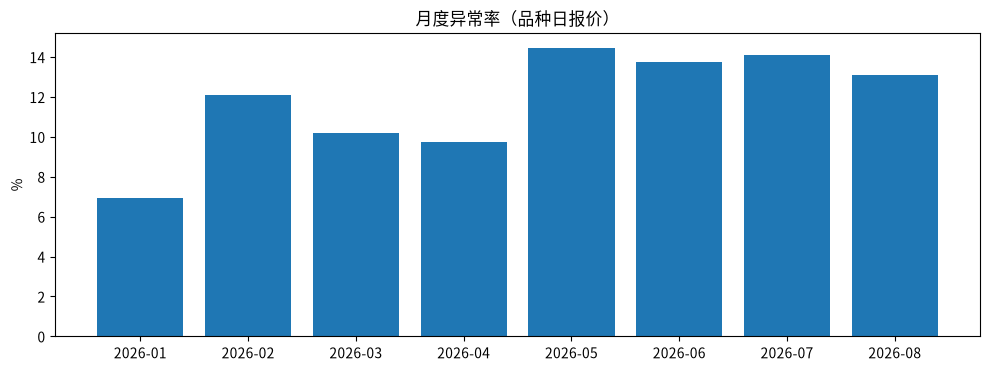

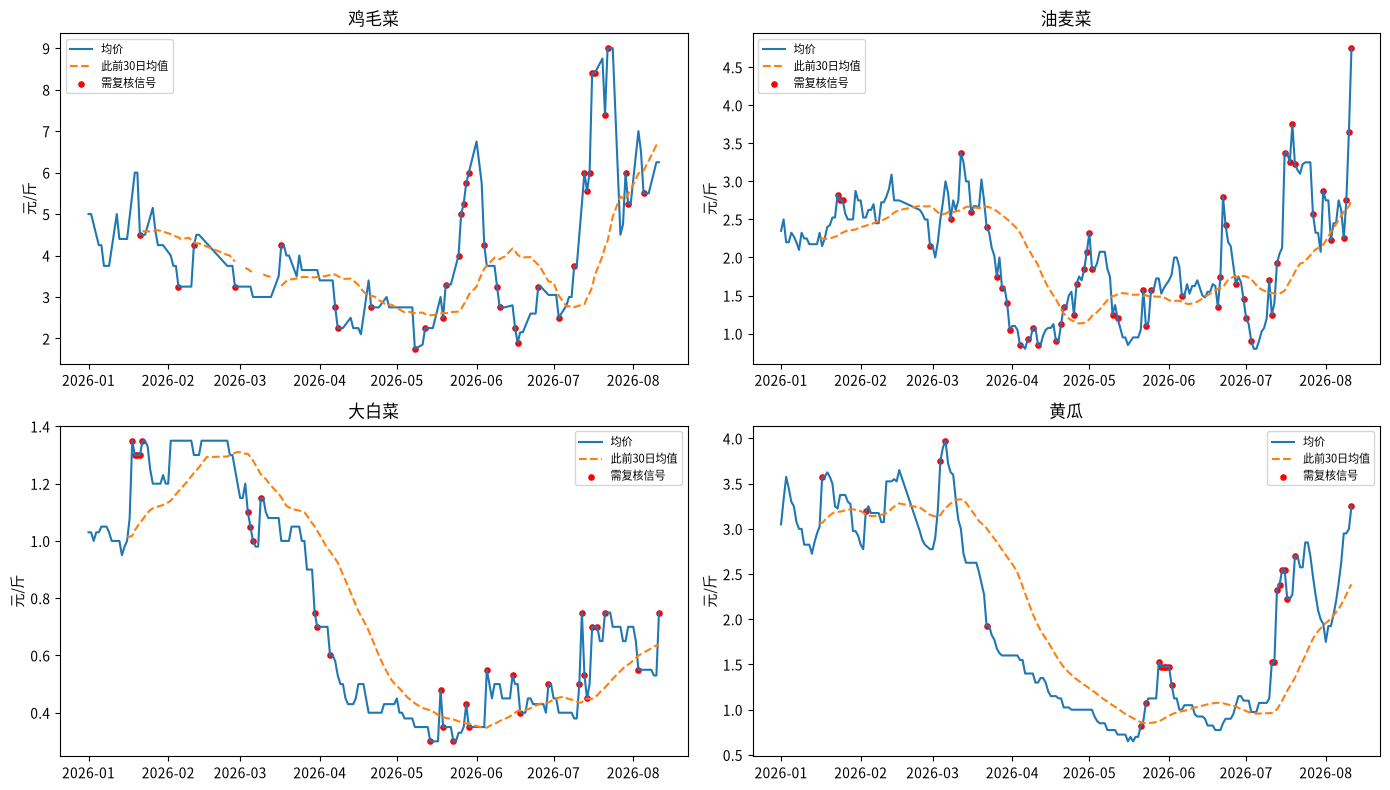

,product,avg_price,price_pct_ch,origin
1630,圆白菜,1.15,1.090909,冀
2062,大白菜,0.75,0.415094,冀
4849,广茄,0.85,0.000000,冀
5887,散叶生菜,2.50,0.000000,冀
6040,散生菜,3.25,0.101695,
6451,木耳菜,4.00,0.066667,
7099,板栗南瓜,1.40,0.000000,桂/蒙
7315,架豆,5.00,0.000000,云/冀
7531,柿子椒,1.95,0.000000,鲁
7900,毛冬瓜,0.90,0.125000,冀/豫/鲁


In [5]:
monthly = v.groupby(v.date.dt.to_period('M')).agg(
    n_records=('date', 'size'), n_anomalies=('anomaly_any', 'sum'),
    anomaly_rate=('anomaly_any', 'mean'), n_surge=('surge', 'sum'), n_crash=('crash', 'sum'))
print(monthly.to_string())
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(monthly.index.astype(str), monthly.anomaly_rate * 100)
ax.set(title='月度异常率（品种日报价）', ylabel='%')
fig.tight_layout()
fig.savefig(OUT / 'figures' / 'eda_monthly.png', dpi=150)
plt.show()

cases = ['鸡毛菜', '油麦菜', '大白菜', '黄瓜']
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, product in zip(axes.ravel(), cases):
    part = v[v["product"].eq(product)]
    ax.plot(part.date, part.avg_price, label='均价')
    ax.plot(part.date, part.rolling_mean, linestyle='--', label='此前30日均值')
    marked = part[part.anomaly_any]
    ax.scatter(marked.date, marked.avg_price, color='red', s=14, label='需复核信号')
    ax.set(title=product, ylabel='元/斤')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'figures' / 'eda_cases.png', dpi=150)
plt.show()
v[v.date.eq(v.date.max()) & v.anomaly_any][['product', 'avg_price', 'price_pct_ch', 'origin']].head(12)

## 5. 时间分段回放与阈值敏感性

九组预设组合分别统计开发期（1–5月）、验证期（6月）与留出期（7月–8月11日）。
这是事后回放，没有使用留出期来选择最优阈值。跨分段的历史报价可作为后续日的基准。
比较异常率、日均复核数与每日复核数P95；不把检测数量当成预测准确率。
后续第3日变化只用于事后描述，缺失报价不可评估，不参与信号生成。

     period  z_threshold  surge_pct  crash_pct  n_records  observed_days  calendar_days  n_alerts  alert_rate  alerts_per_calendar_day  p95_daily_alerts  n_forward_alerts  n_forward_nonalerts  forward_abs_5pct_alert_rate  forward_abs_5pct_nonalert_rate
development          3.0       0.15      -0.12      14874            144            151      1574    0.105822                10.423841             21.50              1432                11737                     0.530726                        0.352390
 validation          3.0       0.15      -0.12       3135             30             30       431    0.137480                14.366667             21.65               396                 2448                     0.550505                        0.396650
    holdout          3.0       0.15      -0.12       4353             42             42       602    0.138295                14.333333             24.95               502                 3136                     0.579681                     

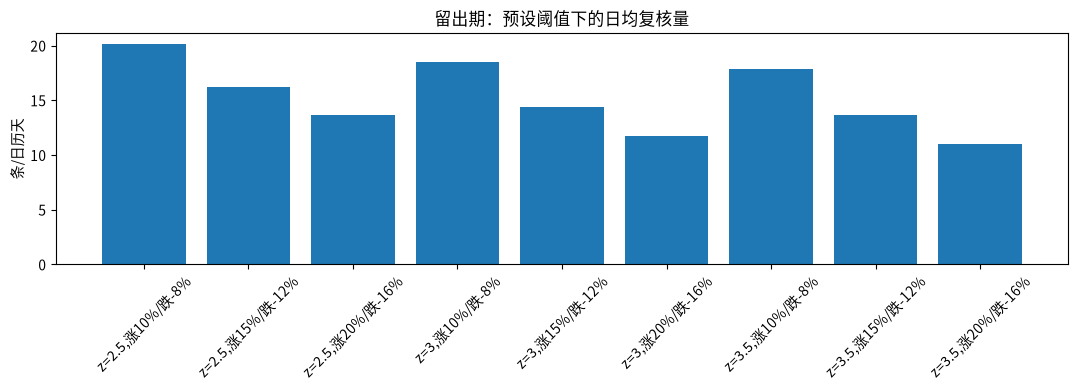

In [6]:
evaluation_table = evaluation.evaluate(features)
baseline = evaluation_table[evaluation_table.z_threshold.eq(3) & evaluation_table.surge_pct.eq(.15)]
print(baseline.to_string(index=False))
holdout = evaluation_table[evaluation_table.period.eq('holdout')].copy()
holdout['setting'] = holdout.apply(lambda r: f"z={r.z_threshold:g},涨{r.surge_pct:.0%}/跌{r.crash_pct:.0%}", axis=1)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(holdout.setting, holdout.alerts_per_calendar_day)
ax.tick_params(axis='x', rotation=45)
ax.set(title='留出期：预设阈值下的日均复核量', ylabel='条/日历天')
fig.tight_layout()
fig.savefig(OUT / 'figures' / 'threshold_workload.png', dpi=150)
plt.show()

## 6. SQL 分析与跨工具校验

SQLite 查询见 sql/analysis.sql：ROW_NUMBER 防重复导入、LAG 计算有效日环比、GROUP BY 月度异常率、gaps-and-islands 连续异常。
SQL 对已聚合数据的去重只用于防重复导入，不能替代原始多规格报价的聚合。
以下对所有日环比及月度指标进行 SQL/Python 一致性断言。

In [7]:
with sqlite3.connect(':memory:') as connection:
    sql_monthly, sql_runs = sql_analysis.analyze(v, connection)
print(f'SQL/Python 一致性通过：{len(v):,} 条日环比与 {len(sql_monthly)} 个月度指标')
print(sql_monthly.to_string(index=False))
sql_runs.head(10)

SQL/Python 一致性通过：22,362 条日环比与 8 个月度指标
  month  n_records  n_anomalies  anomaly_rate  n_surge  n_crash  n_origin_shift
2026-01       3192          221      0.069236       54       44               8
2026-02       2140          259      0.121028       43       61               2
2026-03       3226          328      0.101674       67      118              19
2026-04       3116          303      0.097240       66      113              33
2026-05       3200          463      0.144687      113      132              17
2026-06       3135          431      0.137480       96      155              26
2026-07       3238          456      0.140828      125      122              12
2026-08       1115          146      0.130942       46       37               8


,product,start_date,end_date,consecutive_days
0,大葱,2026-05-04,2026-05-31,28
1,南北瓜,2026-01-28,2026-02-07,11
2,小黄瓜,2026-07-11,2026-07-21,11
3,圆白菜,2026-06-01,2026-06-10,10
4,扁豆,2026-05-23,2026-06-01,10
5,散叶生菜,2026-05-25,2026-06-03,10
6,番茄,2026-07-24,2026-08-02,10
7,冬瓜,2026-06-03,2026-06-11,9
8,卞萝卜,2026-05-08,2026-05-16,9
9,土豆,2026-03-12,2026-03-20,9


## 7. 业务落地与效果验证边界

看板 outputs/veg_report_index.html 展示数据末日的复核队列，可搜索品种，并披露历史风险与数据覆盖。
复核路径：核实日期/规格/单位 → 联系供应商确认 → 结合真实库存、需求和损耗决定动作 → 留下复核记录。

运行 `python scripts/evaluate_monitor.py` 可导出九组阈值结果与120条固定种子的分层复核样本。
manual_review_sample.csv 的标签留空；需人工填写 confirmed/data_issue/normal/uncertain 及证据。
分层样本不能直接估计总体精确率；独立评估集及真实使用记录尚未建立。
不能声称已降低成本、已验证误报率、已证明年度季节性或天气因果。

后续研究需补充多个年度、多市场、天气与成交量数据，先验证业务需求，再决定是否引入季节模型。